## CA01 - Statistical Analysis 

### Daily Wellness and Performance 

### Web form - https://docs.google.com/forms/d/e/1FAIpQLScQsShy4GjzI6Np9ydrJ83kdp1VMr0MHepEgPIGFGyQLqPjLA/viewform?usp=dialog

#### CSV file available on github and submitted to Moodle

In [1]:
#Libraries
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import seaborn as sns 

In [2]:
#Dataset
df_original = pd.read_csv("Data_CA01.csv")

In [3]:
df_original.tail()

,Timestamp,How old are you?,Do you do any kind of exercise?,How many days per week do you exercise?,"On average, how many hours do you sleep per night?",How would you rate your sleep?,How consistent is your bedtime?,Do you track calories or manage your weight?,How many supplements do you take per day?,How many litres of water do you drink every day?,"Do you drink coffee? If so, how many cups of coffee per day?","If you had the opportunity to use GLP-1 medication to lose weight, would you?",How would you rate your daily energy and productivity levels?,How many hours of phone screen time do you have every day?
42,2026/10/01 7:20:56 pm CET,24,Yes,6,8.0,3,Varies a lot,3,2,2.0,2,No,3,3.0
43,2026/10/01 9:32:19 pm CET,33,Yes,2,7.0,4,Varies a lot,3,6,1.5,2,No,2,3.0
44,2026/10/02 1:34:11 pm CET,26,Yes,3,6.5,4,Always the same,2,2,2.0,1,No,4,4.0
45,2026/10/03 11:49:31 am CET,53,Yes,5,6.0,3,I don't have a sleep routine,3,5,2.0,2,Yes,4,3.0
46,2026/10/03 11:54:37 am CET,64,Yes,2,5.6,3,I don't have a sleep routine,3,5,2.0,3,Yes,3,3.6


In [4]:
df = df_original.copy() 

In [5]:
df = df.rename(columns={"How old are you?": "Age",
                        "Do you do any kind of exercise? ": "Exercise_YesNo",
                        "How many days per week do you exercise? ": "Exercise_Days",
                        "On average, how many hours do you sleep per night? ": "Sleep_Hours",
                        "How would you rate your sleep?": "Sleep_Score",
                        "How consistent is your bedtime?": "Bedtime_Rate",
                        "Do you track calories or manage your weight? ": "Track_Calories?",
                        "How many supplements do you take per day?": "Supplement_Per_Day",
                        "How many litres of water do you drink every day? ":"Water_Liters",
                        "Do you drink coffee? If so, how many cups of coffee per day? ": "Coffee_Amount",
                        "If you had the opportunity to use GLP-1 medication to lose weight, would you? ": "GLP1_YesNo",
                        "How would you rate your daily energy and productivity levels?": "Daily_Energy",
                        "How many hours of phone screen time do you have every day?": "Screen_Time",})

df = df.drop(columns=["Timestamp"])
df.head()

,Age,Exercise_YesNo,Exercise_Days,Sleep_Hours,Sleep_Score,Bedtime_Rate,Track_Calories?,Supplement_Per_Day,Water_Liters,Coffee_Amount,GLP1_YesNo,Daily_Energy,Screen_Time
0,28,Yes,5,8.0,4,Always the same,4,2,2.0,1,Yes,3,2.5
1,30,Yes,2,8.0,4,Varies a lot,2,1,1.0,2,No,2,6.0
2,26,Yes,2,7.0,2,I don't have a sleep routine,2,0,2.0,0,No,2,6.0
3,46,Yes,3,8.0,5,Varies a lot,5,2,8.0,1,No,3,4.0
4,40,Yes,2,6.0,3,Varies a lot,3,2,1.5,2,No,2,4.0


In [6]:
numeric_columns = ["Age", "Exercise_Days", "Sleep_Hours", "Sleep_Score", "Track_Calories?", "Supplement_Per_Day", "Water_Liters", "Coffee_Amount", "Daily_Energy", "Screen_Time"]

categorical_columns = ["Exercise_YesNo", "Bedtime_Rate", "GLP1_YesNo"]

print("Rows:", len(df))
print("Columns:", len(df.columns))


Rows: 47
Columns: 13


### Descriptive Statistics

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 47 non-null     int64  
 1   Exercise_YesNo      47 non-null     str    
 2   Exercise_Days       47 non-null     int64  
 3   Sleep_Hours         47 non-null     float64
 4   Sleep_Score         47 non-null     int64  
 5   Bedtime_Rate        47 non-null     str    
 6   Track_Calories?     47 non-null     int64  
 7   Supplement_Per_Day  47 non-null     int64  
 8   Water_Liters        47 non-null     float64
 9   Coffee_Amount       47 non-null     int64  
 10  GLP1_YesNo          47 non-null     str    
 11  Daily_Energy        47 non-null     int64  
 12  Screen_Time         47 non-null     float64
dtypes: float64(3), int64(7), str(3)
memory usage: 5.9 KB


In [8]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,47.0,37.723404,12.303591,24.0,28.0,33.0,44.0,64.0
Exercise_Days,47.0,3.000000,1.853317,0.0,2.0,3.0,5.0,7.0
Sleep_Hours,47.0,6.641489,1.002948,4.0,6.0,7.0,7.0,8.0
Sleep_Score,47.0,3.319149,1.002310,1.0,3.0,3.0,4.0,5.0
Track_Calories?,47.0,2.659574,1.355770,1.0,2.0,2.0,4.0,5.0
Supplement_Per_Day,47.0,2.255319,2.047990,0.0,0.5,2.0,3.5,7.0
Water_Liters,47.0,1.897872,1.139697,0.0,1.5,2.0,2.0,8.0
Coffee_Amount,47.0,1.872340,1.689057,0.0,1.0,2.0,2.5,10.0
Daily_Energy,47.0,3.340426,0.787859,2.0,3.0,3.0,4.0,5.0
Screen_Time,47.0,3.597872,1.583267,0.5,2.5,3.6,4.0,9.0


In [9]:
numeric_summary = pd.DataFrame({'Mean': df[numeric_columns].mean(),'Median': df[numeric_columns].median(),'Mode': df[numeric_columns].mode().iloc[0]})
numeric_summary.round(2)

,Mean,Median,Mode
Age,37.72,33.0,28.0
Exercise_Days,3.00,3.0,2.0
Sleep_Hours,6.64,7.0,7.0
Sleep_Score,3.32,3.0,4.0
Track_Calories?,2.66,2.0,2.0
Supplement_Per_Day,2.26,2.0,2.0
Water_Liters,1.90,2.0,2.0
Coffee_Amount,1.87,2.0,2.0
Daily_Energy,3.34,3.0,3.0
Screen_Time,3.60,3.6,4.0


In [10]:
df[categorical_columns].describe()

,Exercise_YesNo,Bedtime_Rate,GLP1_YesNo
count,47,47,47
unique,2,3,2
top,Yes,Always the same,No
freq,39,20,33


In [11]:
for column in categorical_columns: 
    print(df[column].value_counts())
    print()

Exercise_YesNo
Yes    39
No      8
Name: count, dtype: int64

Bedtime_Rate
Always the same                 20
Varies a lot                    18
I don't have a sleep routine     9
Name: count, dtype: int64

GLP1_YesNo
No     33
Yes    14
Name: count, dtype: int64



In [12]:
df.isnull().sum()

Age                   0
Exercise_YesNo        0
Exercise_Days         0
Sleep_Hours           0
Sleep_Score           0
Bedtime_Rate          0
Track_Calories?       0
Supplement_Per_Day    0
Water_Liters          0
Coffee_Amount         0
GLP1_YesNo            0
Daily_Energy          0
Screen_Time           0
dtype: int64

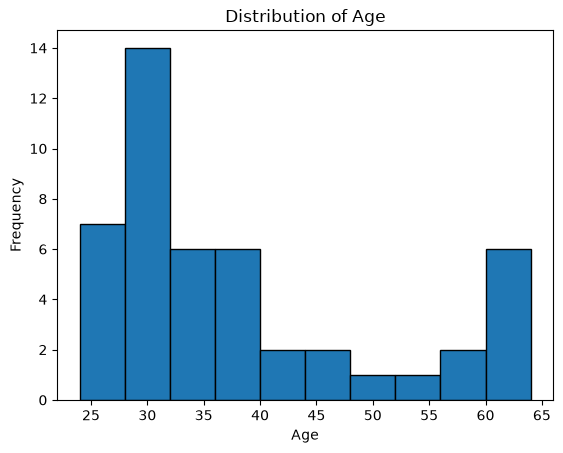

In [13]:
plt.hist(df['Age'], bins=10, edgecolor='black')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

Text(0.5, 1.0, 'Investigation - Distribution of Age')

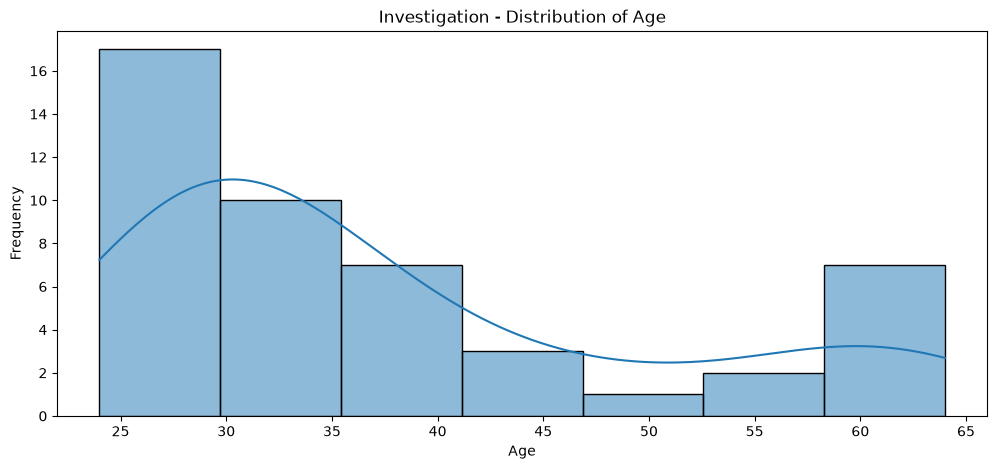

In [14]:
#Checking bimodal distribution of age
plt.figure(figsize = (12,5))
sns.histplot(df["Age"],kde=True)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Investigation - Distribution of Age")

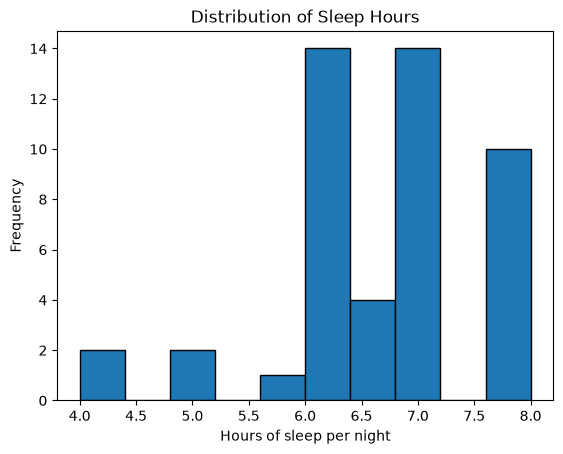

In [15]:
plt.hist(df["Sleep_Hours"], bins = 10, edgecolor = "black")
plt.title("Distribution of Sleep Hours")
plt.xlabel("Hours of sleep per night")
plt.ylabel("Frequency")
plt.show()

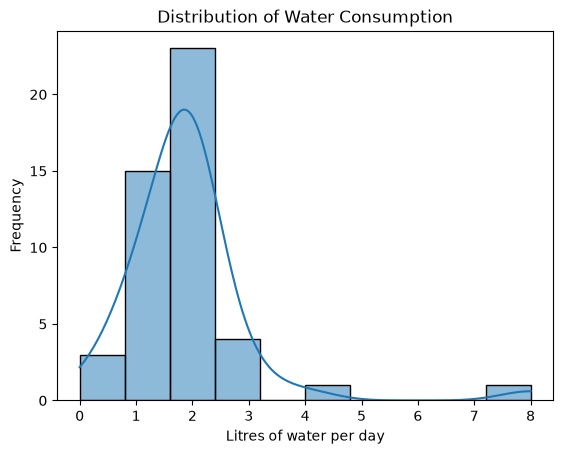

In [16]:
sns.histplot(df["Water_Liters"], bins=10, kde=True, edgecolor='black')
plt.title('Distribution of Water Consumption')
plt.xlabel('Litres of water per day')
plt.ylabel('Frequency')
plt.show()

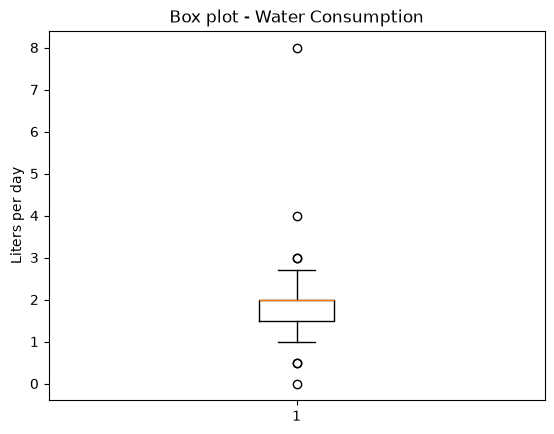

In [17]:
plt.boxplot(df["Water_Liters"])
plt.title("Box plot - Water Consumption")
plt.ylabel("Liters per day")
plt.show()

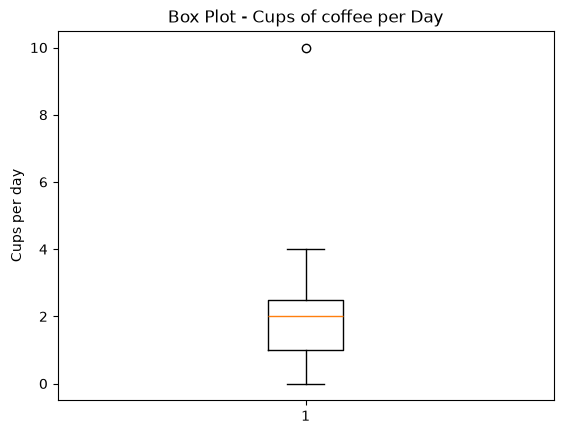

In [18]:
plt.boxplot(df["Coffee_Amount"])
plt.title("Box Plot - Cups of coffee per Day")
plt.ylabel("Cups per day")
plt.show()

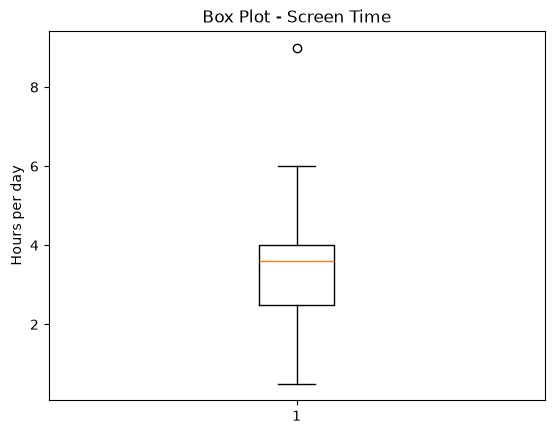

In [19]:
plt.boxplot(df["Screen_Time"])
plt.title("Box Plot - Screen Time")
plt.ylabel("Hours per day")
plt.show()

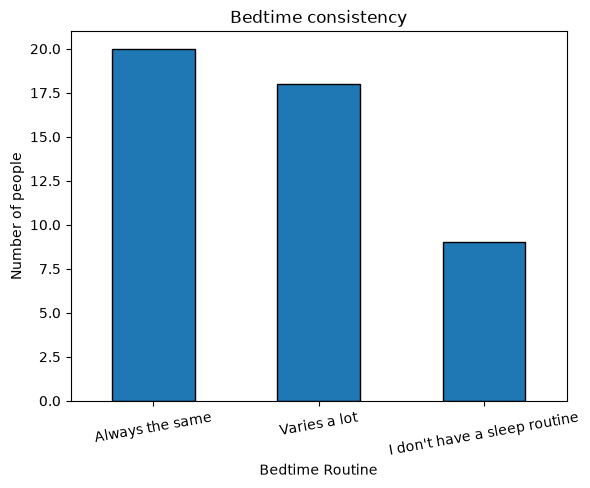

In [20]:
df["Bedtime_Rate"].value_counts().plot(kind="bar", edgecolor= "black")
plt.title("Bedtime consistency")
plt.xlabel("Bedtime Routine")
plt.ylabel("Number of people")
plt.xticks(rotation=10)
plt.show()

### Normality Test

In [21]:
for column in numeric_columns:
    stat, p_value = stats.shapiro(df[column])
    print(f"{column} - stat: {stat: .3f}, p-value: {p_value: .4f}")

    if p_value >=0.05:
        print("Sample is normally distributed.")
    else:
        print("Sample NOT normally distributed.")
    print()

Age - stat:  0.821, p-value:  0.0000
Sample NOT normally distributed.

Exercise_Days - stat:  0.940, p-value:  0.0182
Sample NOT normally distributed.

Sleep_Hours - stat:  0.900, p-value:  0.0007
Sample NOT normally distributed.

Sleep_Score - stat:  0.894, p-value:  0.0005
Sample NOT normally distributed.

Track_Calories? - stat:  0.883, p-value:  0.0002
Sample NOT normally distributed.

Supplement_Per_Day - stat:  0.882, p-value:  0.0002
Sample NOT normally distributed.

Water_Liters - stat:  0.657, p-value:  0.0000
Sample NOT normally distributed.

Coffee_Amount - stat:  0.772, p-value:  0.0000
Sample NOT normally distributed.

Daily_Energy - stat:  0.842, p-value:  0.0000
Sample NOT normally distributed.

Screen_Time - stat:  0.930, p-value:  0.0078
Sample NOT normally distributed.



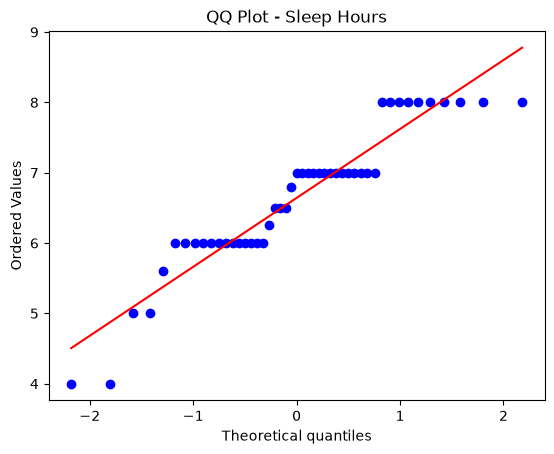

In [22]:
stats.probplot(df["Sleep_Hours"], dist="norm", plot=plt)
plt.title("QQ Plot - Sleep Hours")
plt.show()

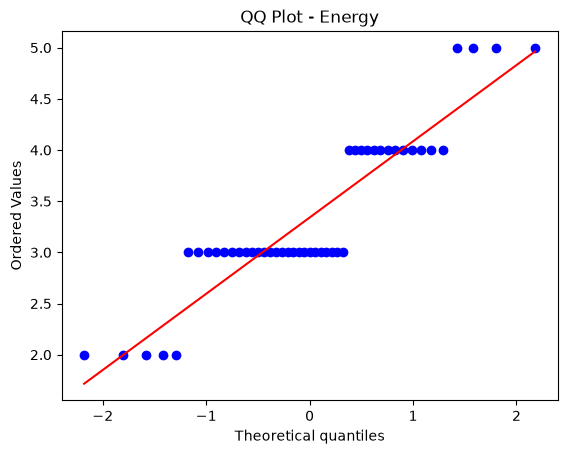

In [23]:
stats.probplot(df["Daily_Energy"], dist="norm", plot=plt)
plt.title("QQ Plot - Energy")
plt.show()

## Outliers on Water consumption

In [24]:
#Outliers for Water_Liters
Q1 = df["Water_Liters"].quantile(0.25)
Q3 = df["Water_Liters"].quantile(0.75)
IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = df[(df["Water_Liters"] < lower_fence) | (df["Water_Liters"] > upper_fence)]["Water_Liters"]

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower fence: {lower_fence}, Upper fence: {upper_fence}")
print(f"Number of outliers: {len(outliers)}")
print("Values:", list(outliers))

Q1: 1.5, Q3: 2.0, IQR: 0.5
Lower fence: 0.75, Upper fence: 2.75
Number of outliers: 7
Values: [8.0, 3.0, 4.0, 0.5, 3.0, 0.0, 0.5]


In [25]:
#Compare the amount of rows on a dataset w/ outliers and w/o outliers
df_no_outliers = df[(df["Water_Liters"] >= lower_fence) & (df["Water_Liters"] <= upper_fence)]

print("Amount of rows with outliers:", len(df))
print("Rows without outliers:", len(df_no_outliers))

Amount of rows with outliers: 47
Rows without outliers: 40


In [26]:
comparison = pd.DataFrame({"With outliers": df["Water_Liters"].describe(),
            "Without outliers": df_no_outliers["Water_Liters"].describe()})

comparison.loc["skewness"] = [df["Water_Liters"].skew(), df_no_outliers["Water_Liters"].skew()]
comparison.loc["kurtosis"] = [df["Water_Liters"].kurt(), df_no_outliers["Water_Liters"].kurt()]

comparison.round(2)

,With outliers,Without outliers
count,47.00,40.00
mean,1.90,1.76
std,1.14,0.43
min,0.00,1.00
25%,1.50,1.50
50%,2.00,2.00
75%,2.00,2.00
max,8.00,2.70
skewness,3.41,-0.51
kurtosis,17.86,-0.29


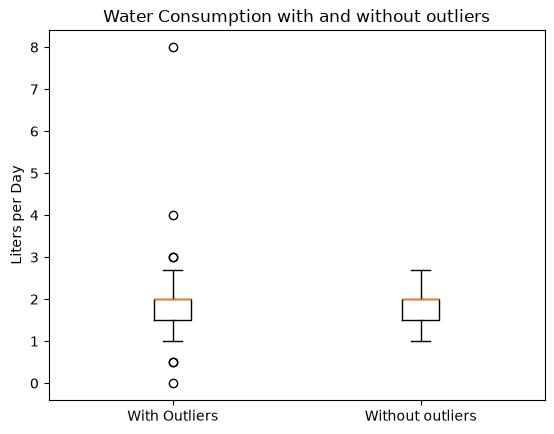

In [27]:
#Box plot showing the water consumption before and after removing outliers
plt.boxplot([df["Water_Liters"], df_no_outliers["Water_Liters"]], tick_labels = ["With Outliers", "Without outliers"])
plt.title("Water Consumption with and without outliers")
plt.ylabel("Liters per Day")
plt.show()

## Sampling and confidence intervals

In [28]:
n = len(df)
sampleMean = df['Sleep_Hours'].mean()
Std = df['Sleep_Hours'].std()

standardError = Std / np.sqrt(n)
t_value = stats.t.ppf(0.975, df=n-1)
confidence_interval = (sampleMean - t_value * standardError, sampleMean + t_value * standardError)

print(f"Sample mean: {sampleMean:.2f}")
print(f"Standard error: {standardError:.3f}")
print(f"t value: {t_value:.3f}")
print(f"95% Confidence interval: ({confidence_interval[0]:.2f}, {confidence_interval[1]:.2f})")

Sample mean: 6.64
Standard error: 0.146
t value: 2.013
95% Confidence interval: (6.35, 6.94)


In [29]:
for column in ["Daily_Energy", "Water_Liters", "Screen_Time", "Exercise_Days"]:
    sampleMean = df[column].mean()
    standardError = df[column].std() / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    confidence_interval = (sampleMean - t_value * standardError, sampleMean + t_value * standardError)

    print(f"{column} - mean: {sampleMean:.2f}, 95% CI: ({confidence_interval[0]:.2f}, {confidence_interval[1]:.2f})")

Daily_Energy - mean: 3.34, 95% CI: (3.11, 3.57)
Water_Liters - mean: 1.90, 95% CI: (1.56, 2.23)
Screen_Time - mean: 3.60, 95% CI: (3.13, 4.06)
Exercise_Days - mean: 3.00, 95% CI: (2.46, 3.54)


In [30]:
sample = df.sample(n=30)

print(f"Mean of Sleep_Hours in the dataset: {df["Sleep_Hours"].mean():.2f}")
print(f"Mean of Sleep_Hours in the sample of 30 responses: {sample["Sleep_Hours"].mean():.2f}")

Mean of Sleep_Hours in the dataset: 6.64
Mean of Sleep_Hours in the sample of 30 responses: 6.51


## Inferential Statistics - Probability and Bayes Theorem

In [31]:
df["High_Energy"] = np.where(df["Daily_Energy"] >= 4, "yes", "no")
df["Trains_Regularly"] = np.where(df["Exercise_Days"] >= 3, "yes", "no")

df[["Daily_Energy", "High_Energy", "Exercise_Days", "Trains_Regularly"]].head(10)

,Daily_Energy,High_Energy,Exercise_Days,Trains_Regularly
0,3,no,5,yes
1,2,no,2,no
2,2,no,2,no
3,3,no,3,yes
4,2,no,2,no
5,5,yes,5,yes
6,3,no,3,yes
7,3,no,4,yes
8,4,yes,5,yes
9,2,no,0,no


In [32]:
pivot = pd.pivot_table(
    df,
    values="Age",
    index="Trains_Regularly",
    columns="High_Energy",
    aggfunc="count",
    margins=True,)
pivot

High_Energy,no,yes,All
Trains_Regularly,,,
no,17,4,21
yes,13,13,26
All,30,17,47


## Conditional Probability

In [33]:
#Overall High energy probability
filtered_High_Energy = df[(df["High_Energy"] == "yes")]

probability = len(filtered_High_Energy) / len(df)
print(f"Probability: {probability:.2%}")

Probability: 36.17%


In [34]:
#Probability of high energy if trained regularly
filtered_Trains = df[(df["Trains_Regularly"] == "yes")]

filtered_trains_and_highenergy = df[(df["Trains_Regularly"] == "yes") & (df["High_Energy"] == "yes")]

probability = len(filtered_trains_and_highenergy) / len(filtered_Trains)
print(f"Probability: {probability:.2%}")

Probability: 50.00%


In [35]:
#Probability of high energy if not trained regularly 
filtered_no_train = df[(df["Trains_Regularly"] == "no")]

filtered_no_train_and_highenergy = df[(df["Trains_Regularly"] == "no") & (df["High_Energy"] == "yes")]

probability = len(filtered_no_train_and_highenergy) / len(filtered_no_train)
print(f"Probability: {probability:.2%}")

Probability: 19.05%


In [36]:
# Probability of having high energy
P1_High_Energy = round(len(df[df["High_Energy"] == "yes"]) / len(df), 3)

# Probability of not having high energy
P2_No_High_Energy = round(1 - P1_High_Energy, 3)

print("P1_High_Energy:", P1_High_Energy)
print("P2_No_High_Energy:", P2_No_High_Energy)

# Probability of training regularly given that the person has high energy
P1_High_Energy_Trains = round(
    len(df[(df["High_Energy"] == "yes")& (df["Trains_Regularly"] == "yes")]) /
    len(df[df["High_Energy"] == "yes"]), 3)

# Probability of training regularly given that the person does not have high energy
P2_No_High_Energy_Trains = round(
    len(df[(df["High_Energy"] == "no") & (df["Trains_Regularly"] == "yes")]) /
    len(df[df["High_Energy"] == "no"]), 3)

print("P1_High_Energy_Trains:", P1_High_Energy_Trains)
print("P2_No_High_Energy_Trains:", P2_No_High_Energy_Trains)

P1_High_Energy: 0.362
P2_No_High_Energy: 0.638
P1_High_Energy_Trains: 0.765
P2_No_High_Energy_Trains: 0.433


In [37]:
Prob_Trains_High_Energy = round(P1_High_Energy_Trains * P1_High_Energy, 3)
Prob_Trains_No_High_Energy = round(P2_No_High_Energy_Trains * P2_No_High_Energy, 3)

print("Prob_Trains_High_Energy:", Prob_Trains_High_Energy)
print("Prob_Trains_No_High_Energy:", Prob_Trains_No_High_Energy)

Prob_Trains_High_Energy: 0.277
Prob_Trains_No_High_Energy: 0.276


In [38]:
#Bayes theorem
Prob_High_Energy = round(Prob_Trains_High_Energy /(Prob_Trains_High_Energy + Prob_Trains_No_High_Energy), 3) 
Prob_High_Energy

0.501

In [39]:
print(f"Prior - probability of high energy: {P1_High_Energy:.1%}")
print(f"Posterior - probability of high energy knowing the person trains regularly: {Prob_High_Energy:.1%}")

Prior - probability of high energy: 36.2%
Posterior - probability of high energy knowing the person trains regularly: 50.1%


## Covariance and Correlation

In [40]:
#covariance
df[numeric_columns].cov().round(2)

,Age,Exercise_Days,Sleep_Hours,Sleep_Score,Track_Calories?,Supplement_Per_Day,Water_Liters,Coffee_Amount,Daily_Energy,Screen_Time
Age,151.38,3.02,-3.38,-1.67,0.38,7.14,-0.45,2.99,1.14,-2.64
Exercise_Days,3.02,3.43,0.40,0.04,1.24,1.48,0.40,-0.09,0.43,-0.15
Sleep_Hours,-3.38,0.40,1.01,0.53,0.20,-0.31,0.09,-0.13,0.00,0.11
Sleep_Score,-1.67,0.04,0.53,1.00,0.18,-0.39,0.19,-0.26,0.24,0.00
Track_Calories?,0.38,1.24,0.20,0.18,1.84,1.28,0.76,-0.28,0.05,-0.13
Supplement_Per_Day,7.14,1.48,-0.31,-0.39,1.28,4.19,0.23,-0.49,0.30,-0.63
Water_Liters,-0.45,0.40,0.09,0.19,0.76,0.23,1.30,-0.37,-0.01,0.26
Coffee_Amount,2.99,-0.09,-0.13,-0.26,-0.28,-0.49,-0.37,2.85,-0.06,-0.13
Daily_Energy,1.14,0.43,0.00,0.24,0.05,0.30,-0.01,-0.06,0.62,-0.10
Screen_Time,-2.64,-0.15,0.11,0.00,-0.13,-0.63,0.26,-0.13,-0.10,2.51


In [41]:
df["Exercise_Days"].cov(df["Daily_Energy"])

np.float64(0.434782608695652)

In [42]:
df["Supplement_Per_Day"].cov(df["Age"])

np.float64(7.137372802960224)

In [43]:
df[numeric_columns].corr().round(2)

,Age,Exercise_Days,Sleep_Hours,Sleep_Score,Track_Calories?,Supplement_Per_Day,Water_Liters,Coffee_Amount,Daily_Energy,Screen_Time
Age,1.00,0.13,-0.27,-0.14,0.02,0.28,-0.03,0.14,0.12,-0.14
Exercise_Days,0.13,1.00,0.22,0.02,0.49,0.39,0.19,-0.03,0.30,-0.05
Sleep_Hours,-0.27,0.22,1.00,0.53,0.14,-0.15,0.08,-0.07,0.00,0.07
Sleep_Score,-0.14,0.02,0.53,1.00,0.13,-0.19,0.17,-0.16,0.30,0.00
Track_Calories?,0.02,0.49,0.14,0.13,1.00,0.46,0.49,-0.12,0.05,-0.06
Supplement_Per_Day,0.28,0.39,-0.15,-0.19,0.46,1.00,0.10,-0.14,0.19,-0.19
Water_Liters,-0.03,0.19,0.08,0.17,0.49,0.10,1.00,-0.19,-0.02,0.14
Coffee_Amount,0.14,-0.03,-0.07,-0.16,-0.12,-0.14,-0.19,1.00,-0.05,-0.05
Daily_Energy,0.12,0.30,0.00,0.30,0.05,0.19,-0.02,-0.05,1.00,-0.08
Screen_Time,-0.14,-0.05,0.07,0.00,-0.06,-0.19,0.14,-0.05,-0.08,1.00


In [44]:
correlation_energy = df[numeric_columns].corr()["Daily_Energy"].drop("Daily_Energy").sort_values(ascending=False)

correlation_energy.round(3)

Sleep_Score           0.300
Exercise_Days         0.298
Supplement_Per_Day    0.187
Age                   0.118
Track_Calories?       0.050
Sleep_Hours           0.001
Water_Liters         -0.016
Coffee_Amount        -0.048
Screen_Time          -0.080
Name: Daily_Energy, dtype: float64

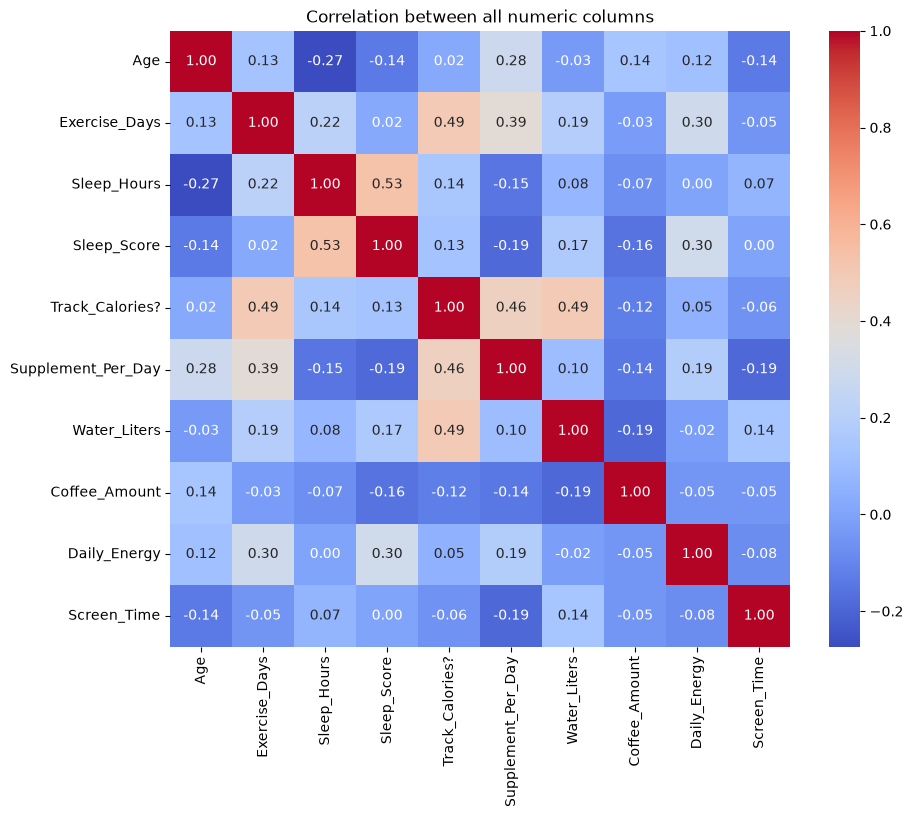

In [45]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between all numeric columns")
plt.show()